## What is Univariate Analysis?
```
The word “univariate” simply means “one variable.”
So, univariate analysis is all about analyzing one column (or feature) of  dataset at a time.
```

## Why Do We Do Univariate Analysis?
```
Before building any machine learning model or drawing any conclusions from your data, it’s important to:

- Understand the data better
- Clean the data if needed
- Find patterns, trends, or outliers
- Choose the right tools or models later
```

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Categorical Data

In [2]:
df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Countplot

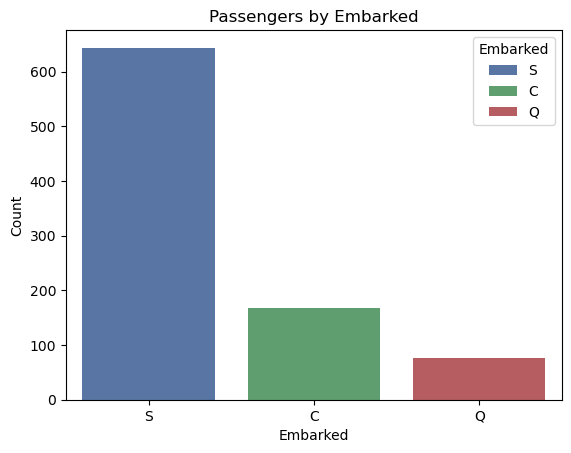

In [3]:
import matplotlib.pyplot as plt

ax = sns.countplot(
    data=df,
    x='Embarked',
    hue='Embarked',
    palette=['#4C72B0', '#55A868', '#C44E52'],
    dodge=False,
    legend=True
)
ax.set_xlabel('Embarked')
ax.set_ylabel('Count')
ax.set_title('Passengers by Embarked')
plt.show()


### PieChart

<Axes: ylabel='count'>

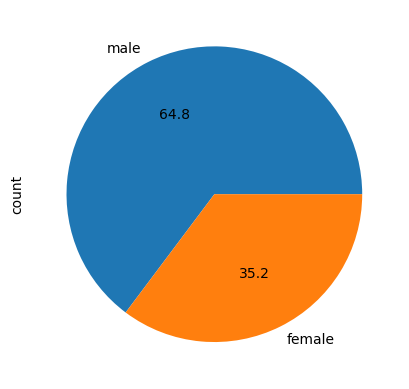

In [4]:
df['Sex'].value_counts().plot(kind='pie',autopct='%.1f')

## Numerical Data

### Histogram

(array([ 54.,  46., 177., 169., 118.,  70.,  45.,  24.,   9.,   2.]),
 array([ 0.42 ,  8.378, 16.336, 24.294, 32.252, 40.21 , 48.168, 56.126,
        64.084, 72.042, 80.   ]),
 <BarContainer object of 10 artists>)

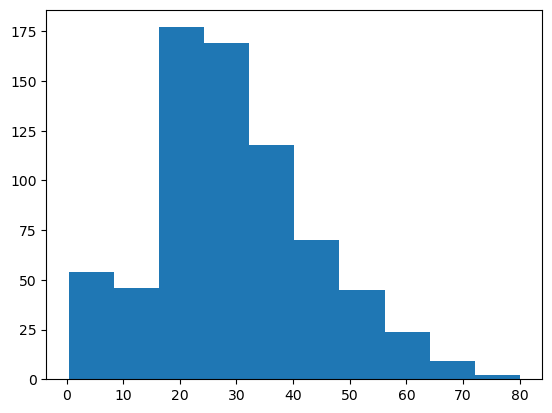

In [5]:
import matplotlib.pyplot as plt
plt.hist(df['Age'],bins=10)

### Histplot (Newer version of distplot)

<Axes: xlabel='Age', ylabel='Count'>

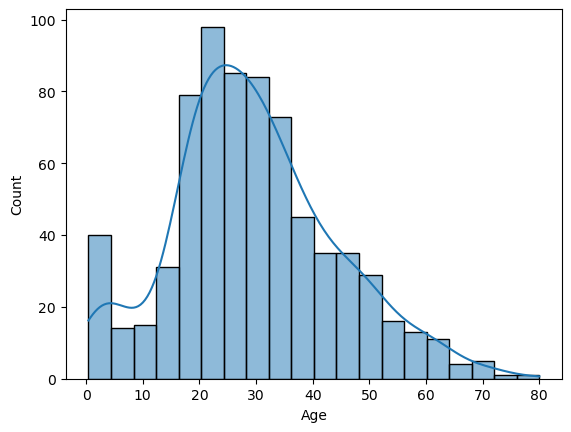

In [6]:
sns.histplot(df['Age'], kde=True)

### Boxplot (Univariate Outlier Detection)
A **Boxplot** is an essential univariate tool to visualize the 5-number summary:
- **Minimum** (Q1 - 1.5 * IQR)
- **First Quartile (Q1 / 25th percentile)**
- **Median (Q2 / 50th percentile)**
- **Third Quartile (Q3 / 75th percentile)**
- **Maximum** (Q3 + 1.5 * IQR)
- **Outliers** (individual points beyond the whiskers)

> **Why use it in univariate analysis?** It immediately flags extreme values and shows whether the distribution is skewed.

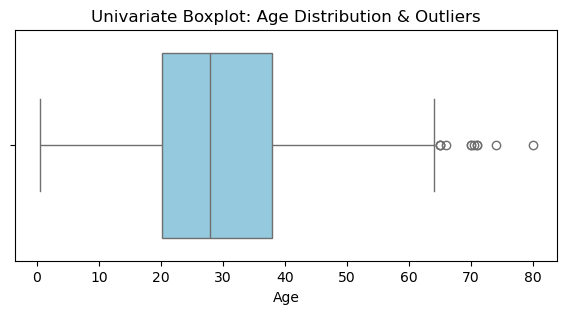

In [7]:
plt.figure(figsize=(7, 3))
sns.boxplot(x=df['Age'], color='skyblue')
plt.title('Univariate Boxplot: Age Distribution & Outliers')
plt.xlabel('Age')
plt.show()

### KDE Plot (Kernel Density Estimate)
A **KDE Plot** visualizes the probability density function of a continuous variable.
Unlike a histogram, which is sensitive to bin count and width, KDE provides a smooth curve showing where data points are concentrated.

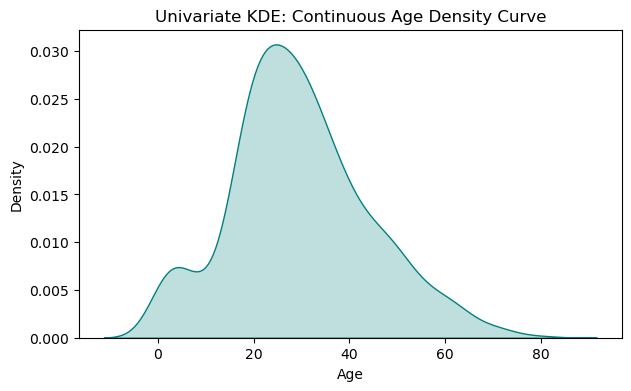

In [8]:
plt.figure(figsize=(7, 4))
sns.kdeplot(df['Age'], fill=True, color='teal')
plt.title('Univariate KDE: Continuous Age Density Curve')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

### Rug Plot
A **Rug Plot** draws small vertical ticks along an axis for every data observation.
It is often combined with KDE or histograms to reveal exact data distribution density and clusters.

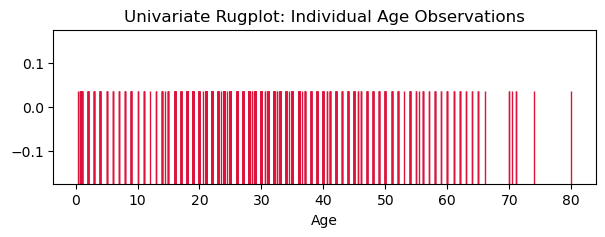

In [9]:
plt.figure(figsize=(7, 2))
sns.rugplot(df['Age'], height=0.6, color='crimson')
plt.title('Univariate Rugplot: Individual Age Observations')
plt.xlabel('Age')
plt.show()

---
# Beyond Univariate: Seaborn's Core Plot Types for Bivariate & Multivariate Analysis
Reference: [Medium: Seaborn's Core Plot Types by Techie Ashu](https://medium.com/@btech.07/seaborns-core-plot-types-7fefba8a9724)

While univariate analysis investigates one variable in isolation, **bivariate and multivariate analysis** uncover relationships, correlations, and interactions between features in `train.csv`.

Seaborn categorizes its core visualizations into **5 major families**:
1. **Relational Plots**: Examine relationships between continuous numerical variables.
2. **Categorical Plots**: Compare distributions or metrics across categorical groups.
3. **Distribution Plots**: Advanced multi-group density and distribution estimation.
4. **Regression Plots**: Linear trend estimation with confidence intervals.
5. **Matrix Plots**: Heatmaps and hierarchical clustering for correlation analysis.

> **Axes-level vs. Figure-level Functions**:
> - *Axes-level* (`scatterplot`, `barplot`, `histplot`, `regplot`) draw onto a single Matplotlib `Axes` and integrate cleanly with subplots.
> - *Figure-level* (`relplot`, `catplot`, `displot`, `lmplot`) manage their own `FacetGrid` to easily create multi-column panels (`col=...`, `row=...`).

## 1. Relational Plots
Relational plots allow us to explore how two or more numeric variables interact, optionally stratified by categorical groupings via `hue`, `size`, or `style`.

### 1.1 `sns.scatterplot()`
**Use Case**: Identify correlation, clusters, and outliers between two continuous variables.
- **`x='Age'`, `y='Fare'`**: Shows whether higher fares were paid by older passengers.
- **`hue='Survived'`**: Color-codes survivors vs. non-survivors.
- **`size='Pclass'`**: Sizes markers according to travel class.

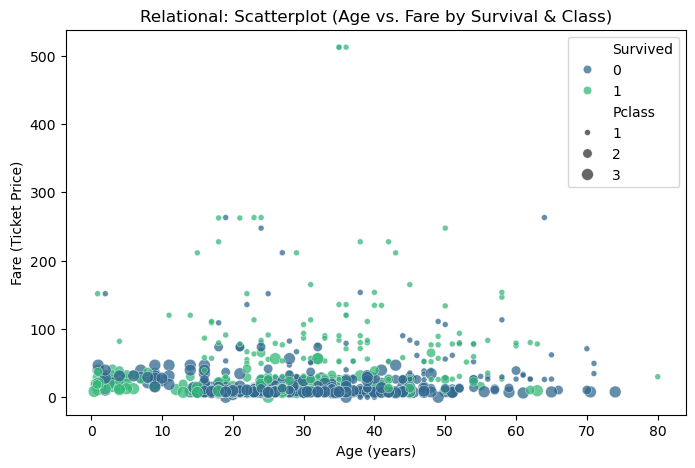

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Age',
    y='Fare',
    hue='Survived',
    size='Pclass',
    palette='viridis',
    alpha=0.75
)
plt.title('Relational: Scatterplot (Age vs. Fare by Survival & Class)')
plt.xlabel('Age (years)')
plt.ylabel('Fare (Ticket Price)')
plt.show()

### 1.2 `sns.lineplot()`
**Use Case**: Track continuous trends or averages across ordered values.
- Displays the mean fare across ages, broken down by passenger class (`hue='Pclass'`).

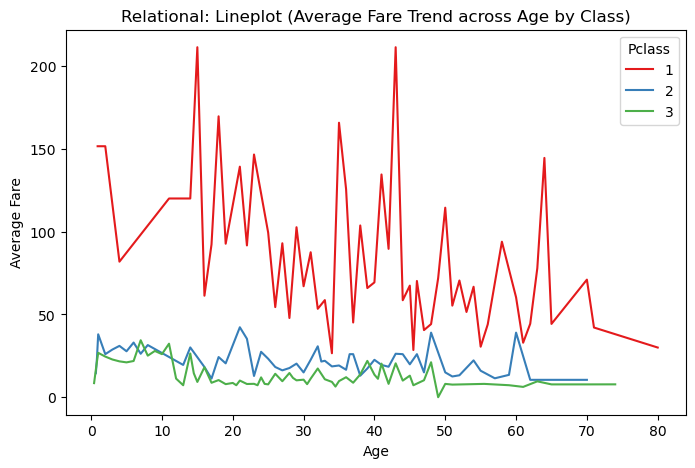

In [11]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df,
    x='Age',
    y='Fare',
    hue='Pclass',
    palette='Set1',
    errorbar=None
)
plt.title('Relational: Lineplot (Average Fare Trend across Age by Class)')
plt.xlabel('Age')
plt.ylabel('Average Fare')
plt.show()

### 1.3 `sns.relplot()` (Figure-level)
**Use Case**: Multi-panel visualization. Automatically splits scatter or line plots across subplots using `col` or `row`.

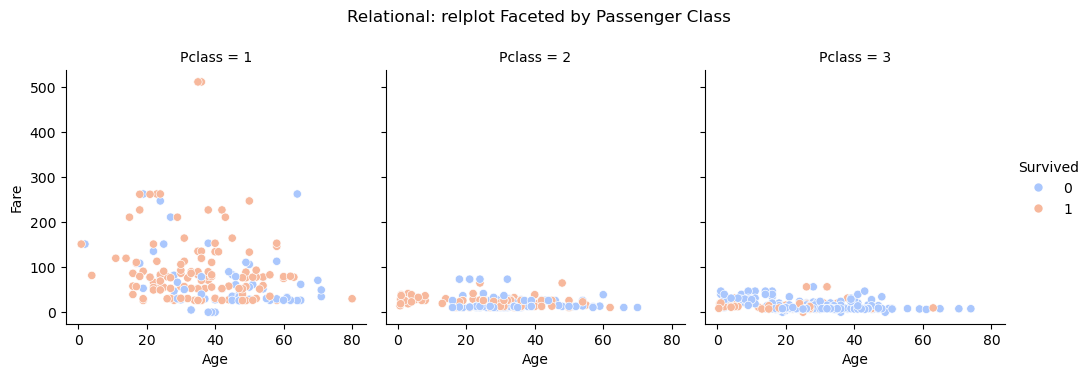

In [12]:
g = sns.relplot(
    data=df,
    x='Age',
    y='Fare',
    hue='Survived',
    col='Pclass',
    kind='scatter',
    palette='coolwarm',
    height=3.8,
    aspect=0.9
)
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle('Relational: relplot Faceted by Passenger Class')
plt.show()

## 2. Categorical Plots
Categorical plots examine relationships involving at least one discrete variable. They are crucial for assessing target rates across demographic categories.

### 2.1 Bivariate `sns.countplot()`
**Use Case**: Compare raw counts within categories stratified by a secondary variable (`hue='Survived'`).

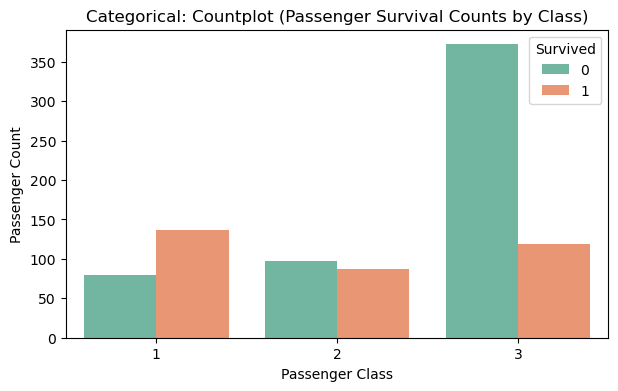

In [13]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Pclass', hue='Survived', palette='Set2')
plt.title('Categorical: Countplot (Passenger Survival Counts by Class)')
plt.xlabel('Passenger Class')
plt.ylabel('Passenger Count')
plt.show()

### 2.2 `sns.barplot()`
**Use Case**: Display aggregated values (defaults to mean) with confidence interval error bars.
- Here, the mean of binary column `Survived` directly represents the **survival rate** (0 to 1 = 0% to 100%).

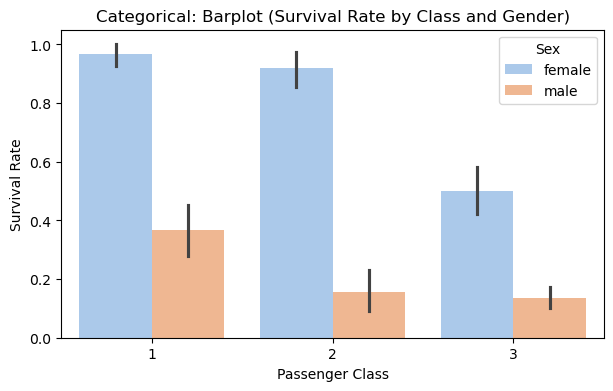

In [14]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', palette='pastel')
plt.title('Categorical: Barplot (Survival Rate by Class and Gender)')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

### 2.3 Grouped `sns.boxplot()`
**Use Case**: Compare distributions of a numeric variable (`Age`) across multiple categorical levels (`Pclass` and `Survived`).

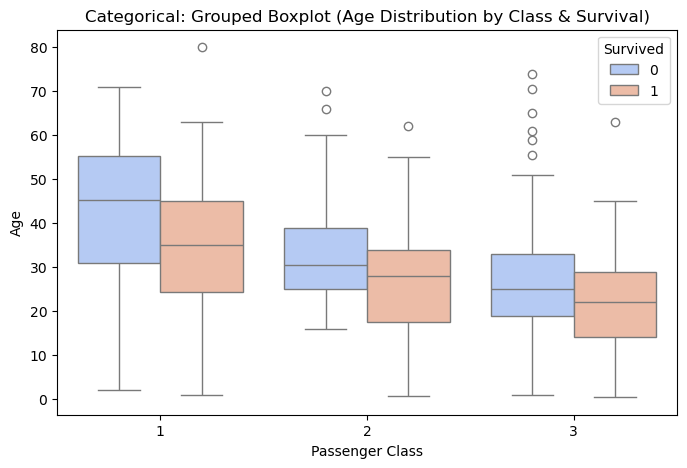

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Pclass', y='Age', hue='Survived', palette='coolwarm')
plt.title('Categorical: Grouped Boxplot (Age Distribution by Class & Survival)')
plt.xlabel('Passenger Class')
plt.ylabel('Age')
plt.show()

### 2.4 `sns.violinplot()`
**Use Case**: Combines the 5-number summary of a boxplot with a mirrored Kernel Density Estimation (KDE).
- Setting `split=True` directly compares the two survival states side-by-side within the same violin.

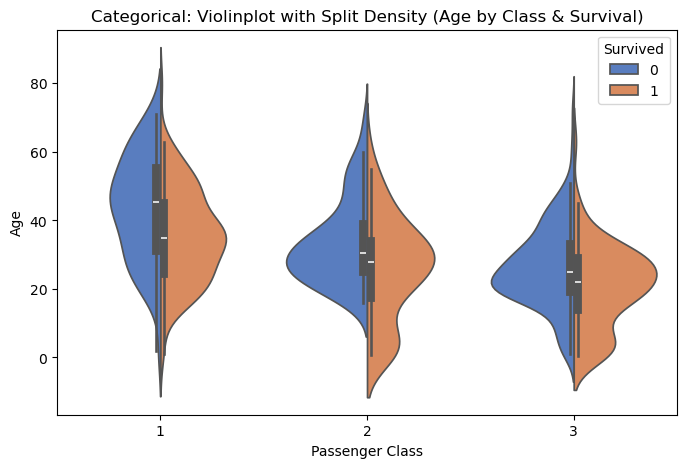

In [16]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='Pclass', y='Age', hue='Survived', split=True, palette='muted')
plt.title('Categorical: Violinplot with Split Density (Age by Class & Survival)')
plt.xlabel('Passenger Class')
plt.ylabel('Age')
plt.show()

### 2.5 `sns.swarmplot()`
**Use Case**: Plots every individual data point adjusted along the categorical axis so that no points overlap.
> *Tip*: For datasets with thousands of points, sub-sampling (e.g. 200 points) preserves clarity and speed.

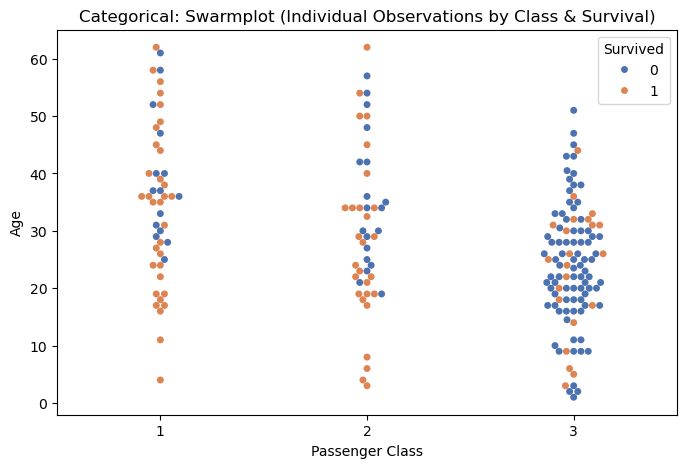

In [17]:
plt.figure(figsize=(8, 5))
sample_df = df.dropna(subset=['Age']).sample(n=200, random_state=42)
sns.swarmplot(data=sample_df, x='Pclass', y='Age', hue='Survived', palette='deep', size=5)
plt.title('Categorical: Swarmplot (Individual Observations by Class & Survival)')
plt.xlabel('Passenger Class')
plt.ylabel('Age')
plt.show()

### 2.6 `sns.pointplot()`
**Use Case**: Highlights changes in mean estimates and slopes across categories. Connecting lines make interaction effects easy to spot.

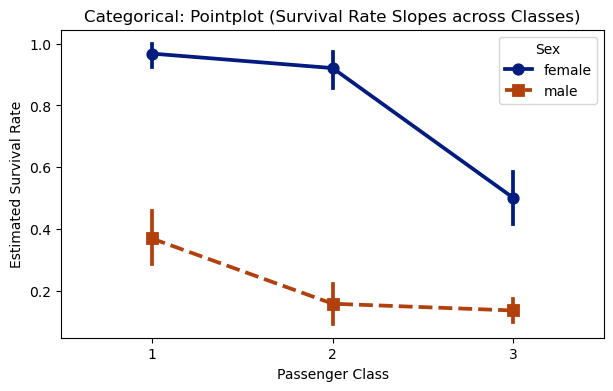

In [18]:
plt.figure(figsize=(7, 4))
sns.pointplot(
    data=df,
    x='Pclass',
    y='Survived',
    hue='Sex',
    palette='dark',
    markers=['o', 's'],
    linestyles=['-', '--']
)
plt.title('Categorical: Pointplot (Survival Rate Slopes across Classes)')
plt.xlabel('Passenger Class')
plt.ylabel('Estimated Survival Rate')
plt.show()

### 2.7 `sns.catplot()` (Figure-level)
**Use Case**: Master figure-level function for categorical plots. Use `kind='bar'`, `'box'`, `'violin'`, or `'count'` combined with `col` to facet across dimensions.

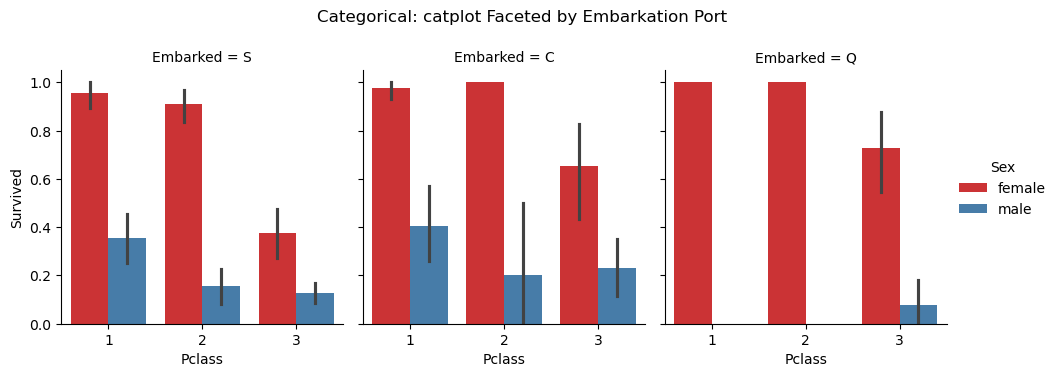

In [19]:
g = sns.catplot(
    data=df.dropna(subset=['Embarked']),
    x='Pclass',
    y='Survived',
    hue='Sex',
    col='Embarked',
    kind='bar',
    palette='Set1',
    height=3.8,
    aspect=0.85
)
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle('Categorical: catplot Faceted by Embarkation Port')
plt.show()

## 3. Advanced Distribution Plots
Modern Seaborn (v0.11+) provides powerful tools to inspect frequency and probability density distributions across categories.

### 3.1 Grouped `sns.histplot()` with KDE
**Use Case**: Replaces the deprecated `distplot`. Comparing histogram bins with an overlay of the smooth KDE line across survival categories.

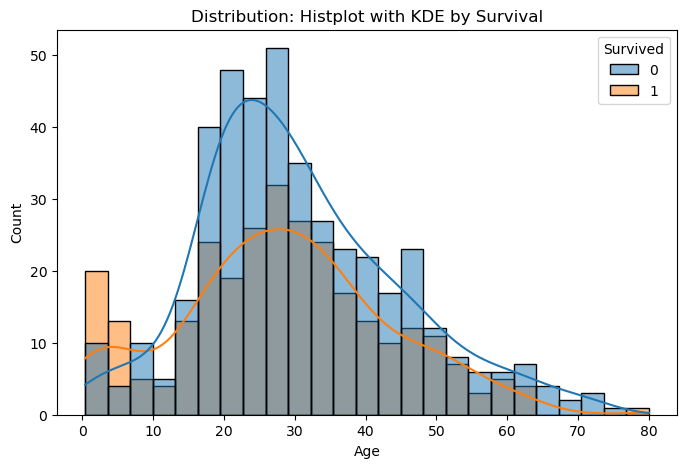

In [20]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', kde=True, hue='Survived', bins=25, palette='tab10')
plt.title('Distribution: Histplot with KDE by Survival')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

### 3.2 Bivariate `sns.kdeplot()`
**Use Case**: Compare continuous density curves between groups. Using `common_norm=False` ensures both curves normalize independently.

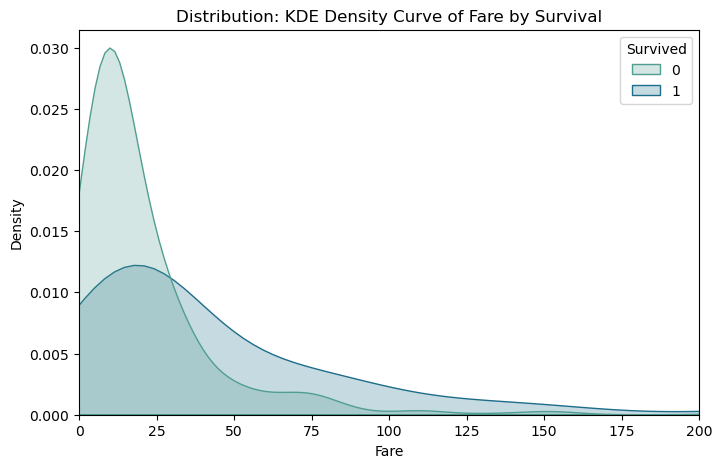

In [21]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='Fare', hue='Survived', fill=True, common_norm=False, palette='crest')
plt.xlim(0, 200)
plt.title('Distribution: KDE Density Curve of Fare by Survival')
plt.xlabel('Fare')
plt.ylabel('Density')
plt.show()

### 3.3 `sns.displot()` (Figure-level)
**Use Case**: Unified distribution plotter capable of generating histograms, KDE curves, or empirical cumulative distributions (`ecdf`) across faceted subplots.

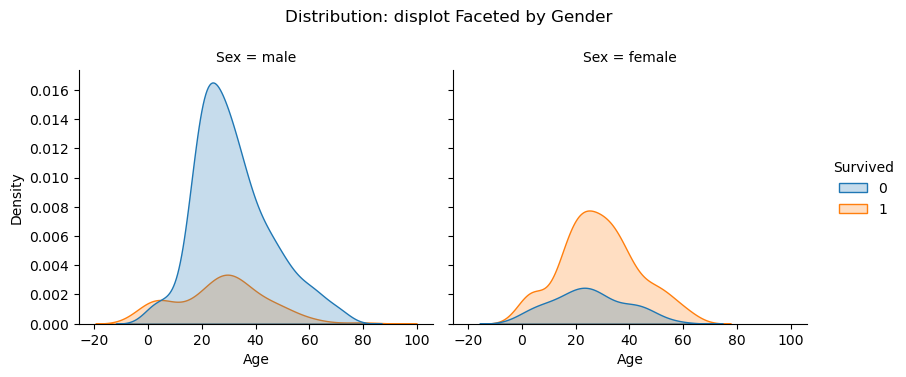

In [22]:
g = sns.displot(data=df, x='Age', hue='Survived', kind='kde', fill=True, col='Sex', height=3.8, aspect=1.1)
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle('Distribution: displot Faceted by Gender')
plt.show()

## 4. Regression Plots
Regression plots fit and display linear relationships between continuous features, adding a regression line and 95% bootstrap confidence interval bands.

### 4.1 `sns.regplot()`
**Use Case**: Fit a simple linear regression model onto a scatter plot.

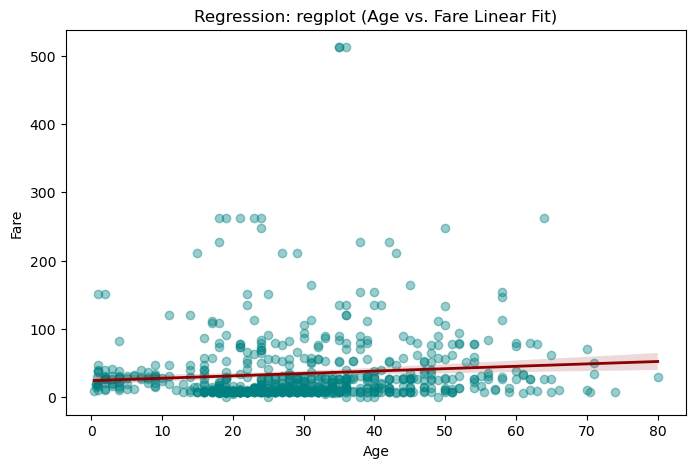

In [23]:
plt.figure(figsize=(8, 5))
clean_df = df.dropna(subset=['Age', 'Fare'])
sns.regplot(
    data=clean_df,
    x='Age',
    y='Fare',
    scatter_kws={'alpha': 0.4, 'color': 'teal'},
    line_kws={'color': 'darkred', 'linewidth': 2}
)
plt.title('Regression: regplot (Age vs. Fare Linear Fit)')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()

### 4.2 `sns.lmplot()` (Figure-level)
**Use Case**: Fit separate linear models conditioned on categorical dimensions using faceting (`col='Pclass'`, `hue='Survived'`).

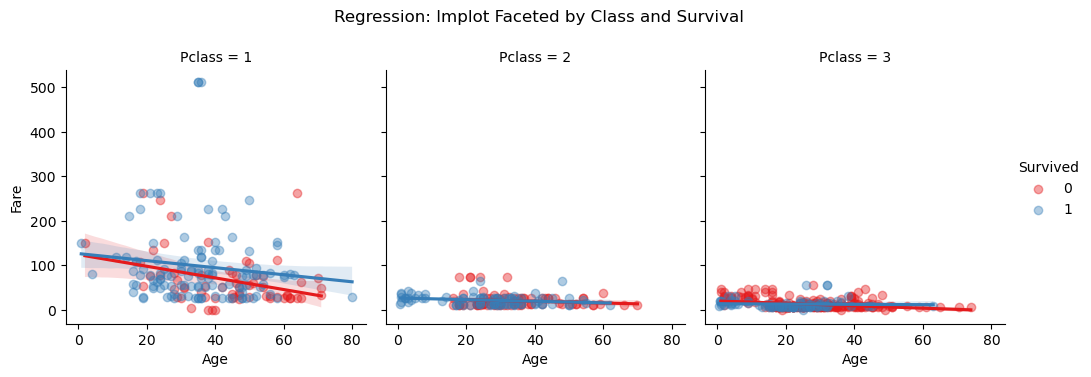

In [24]:
g = sns.lmplot(
    data=clean_df,
    x='Age',
    y='Fare',
    hue='Survived',
    col='Pclass',
    palette='Set1',
    scatter_kws={'alpha': 0.4},
    height=3.8,
    aspect=0.9
)
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle('Regression: lmplot Faceted by Class and Survival')
plt.show()

## 5. Matrix Plots
Matrix plots visualize 2D tables of numbers, such as correlation matrices or cross-tabulations, using color gradients.

### 5.1 `sns.heatmap()`
**Use Case**: Pearson correlation matrix between all numeric features.
- Values near `+1.0` indicate strong positive correlation; values near `-1.0` indicate strong negative correlation.

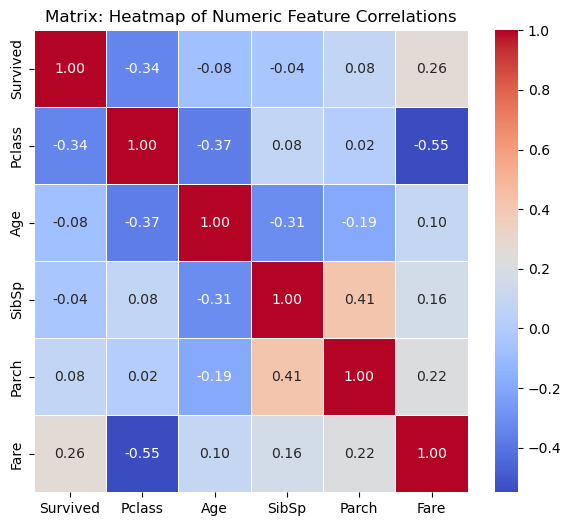

In [25]:
num_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
corr = df[num_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('Matrix: Heatmap of Numeric Feature Correlations')
plt.show()

### 5.2 `sns.clustermap()`
**Use Case**: Combines heatmaps with **hierarchical clustering dendrograms** along the rows and columns, grouping similar features together.

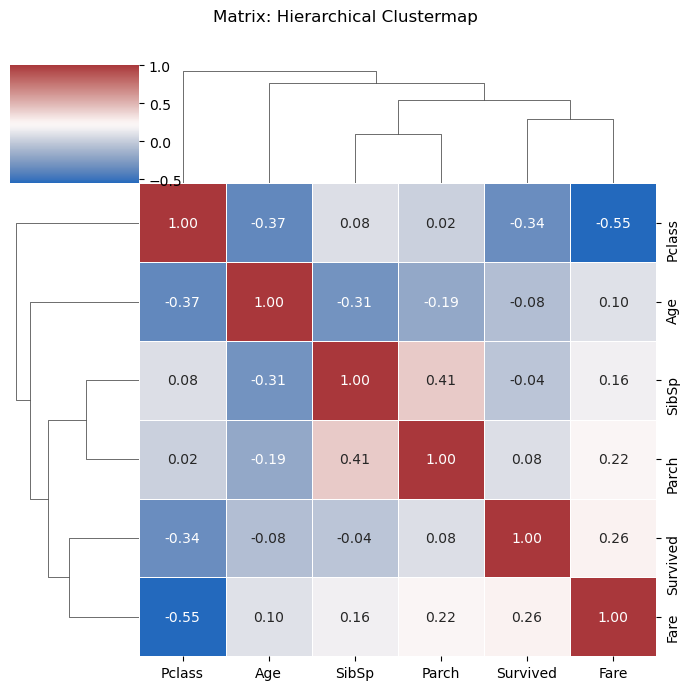

In [26]:
cm = sns.clustermap(corr, annot=True, cmap='vlag', fmt='.2f', figsize=(7, 7), linewidths=0.5)
cm.fig.subplots_adjust(top=0.9)
cm.fig.suptitle('Matrix: Hierarchical Clustermap')
plt.show()

---
## Summary & EDA Plot Selection Cheat Sheet

| Analysis Goal | Recommended Plot | Function |
| :--- | :--- | :--- |
| Single category count | Countplot | `sns.countplot(x=col)` |
| Single numeric spread & outliers | Boxplot / Histplot | `sns.boxplot(x=col)` / `sns.histplot(x=col, kde=True)` |
| Two numeric correlation | Scatterplot / Regplot | `sns.scatterplot(x=num1, y=num2)` / `sns.regplot(...)` |
| Numeric metric by category | Barplot / Pointplot | `sns.barplot(x=cat, y=num)` / `sns.pointplot(...)` |
| Numeric distribution across categories | Boxplot / Violinplot | `sns.boxplot(x=cat, y=num)` / `sns.violinplot(...)` |
| Feature-to-feature correlation | Heatmap / Clustermap | `sns.heatmap(df.corr())` / `sns.clustermap(...)` |
| Multi-dimensional faceting | Relplot / Catplot / Displot | `sns.catplot(col=category)` |